In [5]:
#import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

In [6]:
#import database
conn = sqlite3.connect('E:\PowerBI\Customer churn Project\customer_churn.db')
sql_query = """
        SELECT name
        From sqlite_master
        WHERE type='table'
"""

tables = pd.read_sql(sql_query, conn)

#create dataframe for each table
for table_name in tables['name']:
    df = pd.read_sql(f"SELECT * From {table_name}", conn)
    globals()[f"df_{table_name}"] = df
    print(f"created dataframe: df_{table_name}")

conn.close()


created dataframe: df_db_customer
created dataframe: df_db_subscription
created dataframe: df_db_support


<>:2: SyntaxWarning: invalid escape sequence '\P'
<>:2: SyntaxWarning: invalid escape sequence '\P'
C:\Users\HP\AppData\Local\Temp\ipykernel_1348\1593803648.py:2: SyntaxWarning: invalid escape sequence '\P'
  conn = sqlite3.connect('E:\PowerBI\Customer churn Project\customer_churn.db')


In [7]:
#print table names and column names
conn = sqlite3.connect('E:\PowerBI\Customer churn Project\customer_churn.db')

for table_name in tables['name']:
    print(f"\nTable Name: {table_name}")
    #get column information
    columns_query = f"PRAGMA table_info({table_name});"
    columns = pd.read_sql(columns_query, conn)
    print("columns:")
    print(columns['name'].tolist())

conn.close()
    


Table Name: db_customer
columns:
['customerid', 'name', 'country', 'state', 'gender', 'dob', 'interests', 'pincode']

Table Name: db_subscription
columns:
['customerid', 'subscription_start_date', 'subscription_type', 'renewal_date', 'plan_type', 'contract_type', 'cancellation_date', 'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score']

Table Name: db_support
columns:
['customerid', 'complaint_date', 'escalations', 'csat_score', 'col_1', 'comment']


<>:2: SyntaxWarning: invalid escape sequence '\P'
<>:2: SyntaxWarning: invalid escape sequence '\P'
C:\Users\HP\AppData\Local\Temp\ipykernel_1348\1195837334.py:2: SyntaxWarning: invalid escape sequence '\P'
  conn = sqlite3.connect('E:\PowerBI\Customer churn Project\customer_churn.db')


In [8]:
#data cleaning
df_db_customer.head()

,customerid,name,country,state,gender,dob,interests,pincode
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12 00:00:00,travel,None
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23 00:00:00,NaN,None
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15 00:00:00,movie,None
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30 00:00:00,NaN,None
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05 00:00:00,drama,None


In [9]:
df_db_customer.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   customerid  21 non-null     str   
 1   name        21 non-null     str   
 2   country     18 non-null     str   
 3   state       21 non-null     str   
 4   gender      21 non-null     str   
 5   dob         21 non-null     str   
 6   interests   4 non-null      str   
 7   pincode     0 non-null      object
dtypes: object(1), str(7)
memory usage: 1.4+ KB


In [10]:
#a.rename column - name as customer_name
#b.drop columns - interest and pincode 
#c.change datatype - dob
#d.data standarization - gender
#e.fix missing values - country

In [11]:
#a. rename
df_db_customer.rename(columns = {'name': 'customer_name'},inplace=True)

In [12]:
#b.drop
df_db_customer = df_db_customer.drop(columns = {'interests','pincode'})

In [13]:
df_db_customer

,customerid,customer_name,country,state,gender,dob
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12 00:00:00
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23 00:00:00
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15 00:00:00
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30 00:00:00
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05 00:00:00
5,0013-MHZWF,durga,NaN,Delhi,Women,1988-12-10 00:00:00
6,0013-SMEOE,mina,India,Meghalaya,Female,1976-09-21 00:00:00
7,0014-BMAQU,madan,India,Rajasthan,Male,1999-03-14 00:00:00
8,0015-UOCOJ,maya,NaN,Kathmandu,Women,1985-07-07 00:00:00
9,0016-QLJIS,arjun,Nepal,Kathmandu,Male,1993-10-29 00:00:00


In [14]:
#c. change datatype
df_db_customer['dob'] = pd.to_datetime(df_db_customer['dob'])

In [15]:
#d. data standardization 

df_db_customer['gender'].unique()

<StringArray>
['Male', 'Female', 'Women', 'Men']
Length: 4, dtype: str

In [16]:
df_db_customer['gender'] = df_db_customer['gender'].replace({'Men' : 'Male','Women' : 'Female'})

In [17]:
df_db_customer['gender'].unique()

<StringArray>
['Male', 'Female']
Length: 2, dtype: str

In [18]:
#e. missing value 
df_db_customer[df_db_customer['country'].isna()]

,customerid,customer_name,country,state,gender,dob
5,0013-MHZWF,durga,NaN,Delhi,Female,1988-12-10
8,0015-UOCOJ,maya,NaN,Kathmandu,Female,1985-07-07
12,0018-NYROU,chitra,NaN,Telangana,Female,2004-12-01


In [19]:
df_db_customer[['country','state']]

,country,state
0,India,Maharashtra
1,India,Karnataka
2,India,Delhi
3,India,Nagaland
4,India,Delhi
5,NaN,Delhi
6,India,Meghalaya
7,India,Rajasthan
8,NaN,Kathmandu
9,Nepal,Kathmandu


In [20]:
state_country_map = df_db_customer.dropna(subset=['country']).set_index('state')['country'].to_dict()

df_db_customer['country'] = df_db_customer['country'].fillna(df_db_customer['state'].map(state_country_map))

In [21]:
df_db_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaN,NaN,13.99,627,12
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaN,NaN,6.99,210,34
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaN,NaN,22.99,1725,8
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88


In [22]:
df_db_subscription.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customerid               21 non-null     str    
 1   subscription_start_date  21 non-null     str    
 2   subscription_type        21 non-null     str    
 3   renewal_date             21 non-null     str    
 4   plan_type                21 non-null     str    
 5   contract_type            21 non-null     str    
 6   cancellation_date        6 non-null      str    
 7   cancellation_reason      6 non-null      str    
 8   monthly_charges          21 non-null     float64
 9   cltv                     21 non-null     int64  
 10  churn_score              21 non-null     int64  
dtypes: float64(1), int64(2), str(8)
memory usage: 1.9 KB


In [23]:
#change datatype to date
df_db_subscription['subscription_start_date'] = pd.to_datetime(df_db_subscription['subscription_start_date'])
df_db_subscription['renewal_date'] = pd.to_datetime(df_db_subscription['renewal_date'])
df_db_subscription['cancellation_date'] = pd.to_datetime(df_db_subscription['cancellation_date'])

In [24]:
df_db_support.head()

,customerid,complaint_date,escalations,csat_score,col_1,comment
0,0003-MKNFE,2024-08-28 00:00:00,N,60,None,service issue
1,0003-MKNFE,2024-08-28 00:00:00,Y,10,None,demaned refund
2,0013-EXCHZ,2024-01-20 00:00:00,Y,20,None,NaN
3,0013-MHZWF,2025-03-18 00:00:00,N,90,None,guidance to renew
4,0013-SMEOE,2024-11-01 00:00:00,N,30,None,NaN


In [25]:
df_db_support.info()

<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   customerid      9 non-null      str   
 1   complaint_date  9 non-null      str   
 2   escalations     9 non-null      str   
 3   csat_score      9 non-null      int64 
 4   col_1           0 non-null      object
 5   comment         4 non-null      str   
dtypes: int64(1), object(1), str(4)
memory usage: 564.0+ bytes


In [26]:
df_db_support.drop(columns=['col_1','comment'], inplace=True)

In [27]:
df_db_support.info()

<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   customerid      9 non-null      str  
 1   complaint_date  9 non-null      str  
 2   escalations     9 non-null      str  
 3   csat_score      9 non-null      int64
dtypes: int64(1), str(3)
memory usage: 420.0 bytes


In [28]:
df_db_support['complaint_date'] = pd.to_datetime(df_db_support['complaint_date'])

In [29]:
#Feature Engineering and Data Analysis

In [30]:
df_db_subscription.head(3)

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,12
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,NaN,6.99,210,34


In [31]:
#create a new column using existing column - churn flag
df_db_subscription['churn_flag'] = np.where(df_db_subscription['cancellation_date'].notna(),1,0)

In [32]:
df_db_subscription.head(3)

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score,churn_flag
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,12,0
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,NaN,6.99,210,34,0


In [33]:
#merging all df
df =(df_db_subscription
    .merge(df_db_customer, on = 'customerid', how = 'left')
    .merge(df_db_support, on = 'customerid', how = 'left'))

In [34]:
df.shape                             # firstly it shows 23 rows

(23, 20)

In [35]:
df_db_subscription.shape

(21, 12)

In [36]:
df_db_subscription['customerid'].nunique()               #rows should be same - 21

21

In [37]:
df_db_customer['customerid'].nunique()

21

In [38]:
df_db_support['customerid'].nunique()

7

In [39]:
df_db_support['customerid'].size

9

In [40]:
df_db_support

,customerid,complaint_date,escalations,csat_score
0,0003-MKNFE,2024-08-28,N,60
1,0003-MKNFE,2024-08-28,Y,10
2,0013-EXCHZ,2024-01-20,Y,20
3,0013-MHZWF,2025-03-18,N,90
4,0013-SMEOE,2024-11-01,N,30
5,0017-IUDMW,2024-04-10,Y,25
6,0019-EFAEP,2024-09-27,Y,30
7,0022-TCJCI,2024-09-13,Y,10
8,0022-TCJCI,2024-09-14,N,90


In [41]:
#fixing double customerid
df_db_support['complaint_count'] = df_db_support.groupby('customerid')['customerid'].transform('count')

In [42]:
df_db_support = df_db_support.sort_values('complaint_date').drop_duplicates('customerid', keep='last')

In [43]:
# merge df at above and got same rows 

In [44]:
df.to_csv('exported_churn_data.csv', index=False)

In [45]:
#data analysis

In [46]:
#1. Churn Rate

In [47]:
df.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score'],
      dtype='str')

In [48]:
churn_rate = df['churn_flag'].mean()*100
print("Churn Rate = ",round(churn_rate,2), "%")

Churn Rate =  34.78 %


In [49]:
#2.Retention Rate
retention_rate = 100 - churn_rate
print("Retention Rate = ",round(retention_rate,2), "%")

Retention Rate =  65.22 %


In [50]:
df.head(2)

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score,churn_flag,customer_name,country,state,gender,dob,complaint_date,escalations,csat_score
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,12,0,keshav,India,Maharashtra,Male,1982-04-12,NaT,NaN,NaN
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1,raghav,India,Karnataka,Male,1995-11-23,2024-08-28,N,60.0


In [51]:
#3.Churn by plan type
churn_by_plan = (df.groupby('plan_type')['churn_flag'].mean().mul(100).round(2).reset_index(name='churn_rate_pct'))
print(churn_by_plan)

  plan_type  churn_rate_pct
0     Basic           66.67
1   Premium           25.00
2  Standard           22.22


In [52]:
# 4 a. churn by state
churn_by_state = (df.groupby('state')['churn_flag'].mean().mul(100).round(2).reset_index(name = 'churn_rate_pct'))
print(churn_by_state)

           state  churn_rate_pct
0          Delhi           25.00
1      Karnataka          100.00
2      Kathmandu            0.00
3    Maharashtra            0.00
4      Meghalaya           66.67
5       Nagaland            0.00
6      Rajasthan            0.00
7      Telangana           66.67
8  Uttar Pradesh            0.00


In [53]:
# 4 b. churn by subscription type 
churn_by_subscription = (df.groupby('subscription_type')['churn_flag'].mean().mul(100).round(2).reset_index(name='churn_rate_pct'))
print(churn_by_subscription)

  subscription_type  churn_rate_pct
0           Organic            0.00
1              Paid           28.57
2          Refferal           85.71


In [54]:
#5. ARPU Average revenue per user
arpu = df['monthly_charges'].mean()
print('ARPU = ',round(arpu,2))

ARPU =  18.51


In [55]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 23 entries, 0 to 22
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   customerid               23 non-null     str           
 1   subscription_start_date  23 non-null     datetime64[us]
 2   subscription_type        23 non-null     str           
 3   renewal_date             23 non-null     datetime64[us]
 4   plan_type                23 non-null     str           
 5   contract_type            23 non-null     str           
 6   cancellation_date        8 non-null      datetime64[us]
 7   cancellation_reason      8 non-null      str           
 8   monthly_charges          23 non-null     float64       
 9   cltv                     23 non-null     int64         
 10  churn_score              23 non-null     int64         
 11  churn_flag               23 non-null     int64         
 12  customer_name            23 non-null     str     

In [56]:
df['subscription_start_date'] = pd.to_datetime(df['subscription_start_date'])
df['cancellation_date'] = pd.to_datetime(df['cancellation_date'])

In [57]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 23 entries, 0 to 22
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   customerid               23 non-null     str           
 1   subscription_start_date  23 non-null     datetime64[us]
 2   subscription_type        23 non-null     str           
 3   renewal_date             23 non-null     datetime64[us]
 4   plan_type                23 non-null     str           
 5   contract_type            23 non-null     str           
 6   cancellation_date        8 non-null      datetime64[us]
 7   cancellation_reason      8 non-null      str           
 8   monthly_charges          23 non-null     float64       
 9   cltv                     23 non-null     int64         
 10  churn_score              23 non-null     int64         
 11  churn_flag               23 non-null     int64         
 12  customer_name            23 non-null     str     

In [58]:
#6. Avg customer Tenure
# count of days users has used our service : cancellation date else currrent date

today = pd.Timestamp.today()

df['tenure_days'] = np.where(
    df['cancellation_date'].notna(), 
    
    (df['cancellation_date'] - df['subscription_start_date']).dt.days,
    
    (today - df['subscription_start_date']).dt.days
)

avg_tenure = df['tenure_days'].mean()
print("Avg Tenure (Dyas) = ",round(avg_tenure,2))

Avg Tenure (Dyas) =  1510.22


In [59]:
# 7. Revenue at Risk - revenue lost form churned users
revenue_at_risk = df.loc[df['churn_flag'] == 1, 'monthly_charges'].sum()
print("Revenue at risk (Rs K) = ",revenue_at_risk)

Revenue at risk (Rs K) =  103.91999999999999


In [60]:
# 8. Esclation Rate
escalations_rate = (df['escalations']=='Y').mean()*100
print("escalations rate = ",round(escalations_rate, 2),"%")

escalations rate =  21.74 %


In [61]:
# 9. Avg complaint per user
df['complaint_date'] = pd.to_datetime(df['complaint_date'])
df['complaint_count'] = np.where(df['complaint_date'].notna(),1,0)

In [62]:
df.head(5)

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,...,customer_name,country,state,gender,dob,complaint_date,escalations,csat_score,tenure_days,complaint_count
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,...,keshav,India,Maharashtra,Male,1982-04-12,NaT,NaN,NaN,2046.0,0
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,...,raghav,India,Karnataka,Male,1995-11-23,2024-08-28,N,60.0,1501.0,1
2,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,...,raghav,India,Karnataka,Male,1995-11-23,2024-08-28,Y,10.0,1501.0,1
3,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,NaN,6.99,210,...,lalita,India,Delhi,Female,1978-02-15,NaT,NaN,NaN,1431.0,0
4,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,NaN,22.99,1725,...,mohan,India,Nagaland,Male,2001-08-30,NaT,NaN,NaN,2721.0,0


In [63]:
avg_complaints = df['complaint_count'].sum() / df['customerid'].nunique()
print("Avg Complaints per user = ",round(avg_complaints, 2))

Avg Complaints per user =  0.43


In [64]:
# 10. correlation escalations vs churn
df[['customerid','escalations','churn_flag']].dropna()

,customerid,escalations,churn_flag
1,0003-MKNFE,N,1
2,0003-MKNFE,Y,1
5,0013-EXCHZ,Y,1
6,0013-MHZWF,N,0
7,0013-SMEOE,N,1
12,0017-IUDMW,Y,1
14,0019-EFAEP,Y,1
19,0022-TCJCI,Y,1
20,0022-TCJCI,N,1


In [65]:
df['escalations'] = np.where(df['escalations'] == 'Y', 1,0)

In [66]:
df.head(3)

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,...,customer_name,country,state,gender,dob,complaint_date,escalations,csat_score,tenure_days,complaint_count
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,...,keshav,India,Maharashtra,Male,1982-04-12,NaT,0,NaN,2046.0,0
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,...,raghav,India,Karnataka,Male,1995-11-23,2024-08-28,0,60.0,1501.0,1
2,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,...,raghav,India,Karnataka,Male,1995-11-23,2024-08-28,1,10.0,1501.0,1


In [67]:
corr_df = df[['customerid','escalations','churn_flag']].dropna()

In [68]:
correlation = corr_df['escalations'].corr(df['churn_flag'])
print("Correlation between escalations vs churn is = ", round(correlation, 2))

Correlation between escalations vs churn is =  0.72


In [69]:
# 11. churn risk - create a column using exsiting column
df['churn_score'].head()

0    12
1    91
2    91
3    34
4     8
Name: churn_score, dtype: int64

In [70]:
conditions = [
    (df['churn_score'] < 50),
    (df['churn_score'] >= 50) & (df['churn_score'] < 70),  
    (df['churn_score'] >= 70)
]

choices = ['Low','Medium','High']

df['churn_risk'] = np.select(conditions,choices, default="unknown")
    

In [71]:
df[['churn_risk','churn_score']].head()

,churn_risk,churn_score
0,Low,12
1,High,91
2,High,91
3,Low,34
4,Low,8


In [ ]:
# Visualization - Matplotlib

In [73]:
df_visual = df.copy()


In [75]:
df_visual.shape

(23, 23)

In [76]:
#1. Monthly churn trend (time series KPI)

df_visual['cancellation_date'].dt.to_period('M')

0         NaT
1     2024-09
2     2024-09
3         NaT
4         NaT
5     2024-02
6         NaT
7     2024-11
8         NaT
9         NaT
10        NaT
11        NaT
12    2024-05
13        NaT
14    2024-10
15        NaT
16        NaT
17        NaT
18        NaT
19    2024-09
20    2024-09
21        NaT
22        NaT
Name: cancellation_date, dtype: period[M]

In [87]:
df_visual['cancellation_month'] = df_visual['cancellation_date'].dt.to_period('M')

In [100]:
churn_trend = df_visual[df_visual['churn_flag'] == 1].groupby('cancellation_month').size()

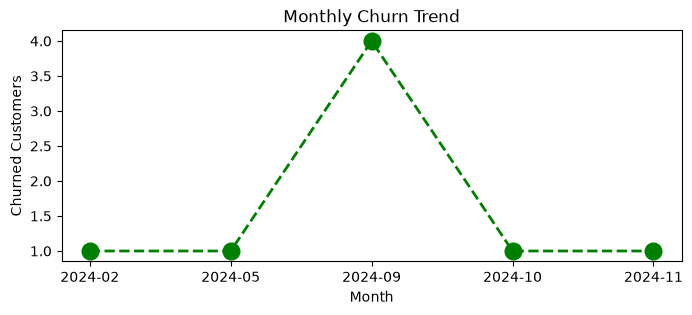

In [101]:
plt.figure(figsize = (8,3))
plt.plot(churn_trend.index.astype(str), churn_trend.values, color='green', marker='o', linestyle='dashed', linewidth=2, markersize=12 )

plt.title('Monthly Churn Trend')
plt.xlabel('Month')
plt.ylabel('Churned Customers')
plt.show()

In [102]:
# 2. Churn by Plan type
df_visual.groupby('plan_type')['churn_flag'].mean()

plan_type
Basic       0.666667
Premium     0.250000
Standard    0.222222
Name: churn_flag, dtype: float64

In [103]:
churn_plan = df_visual.groupby('plan_type')['churn_flag'].mean()

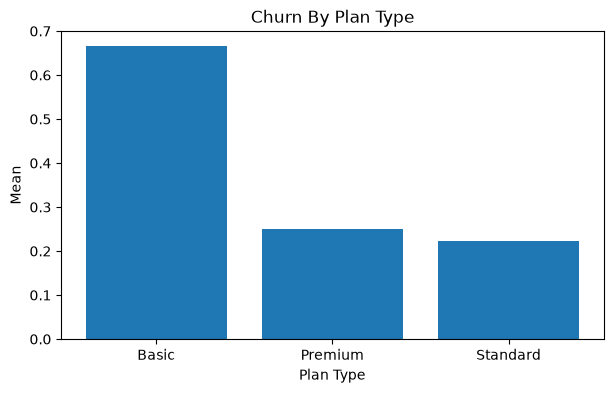

In [108]:
plt.figure(figsize = (7,4))
plt.bar(churn_plan.index, churn_plan.values)

plt.title('Churn By Plan Type')
plt.xlabel('Plan Type')
plt.ylabel('Mean')
plt.show()

In [109]:
# 3. churn by states 

df_visual.groupby('state')['churn_flag'].mean()

state
Delhi            0.250000
Karnataka        1.000000
Kathmandu        0.000000
Maharashtra      0.000000
Meghalaya        0.666667
Nagaland         0.000000
Rajasthan        0.000000
Telangana        0.666667
Uttar Pradesh    0.000000
Name: churn_flag, dtype: float64

In [110]:
churn_state = df_visual.groupby('state')['churn_flag'].mean()

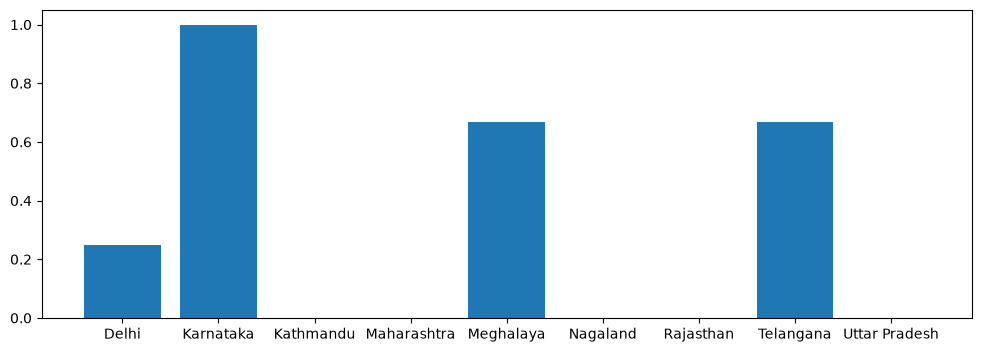

In [112]:
plt.figure(figsize = (12,4))
plt.bar(churn_state.index, churn_state.values)
plt.show()

In [ ]:
# Visualization - Seaborn

In [113]:
# Heatmap (correlation matrix)

sns.heatmap(df_visual.corr(), annot=True)

ValueError: could not convert string to float: '0002-ORFBO'

In [114]:
# encoding - convert str to numeric to find correlation between features
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'tenure_days',
       'complaint_count', 'churn_risk', 'cancellation_month'],
      dtype='str')

In [115]:
#df_encoded 
df_visual[['plan_type', 'contract_type','churn_score','churn_flag','churn_risk', 'escalations']].head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,Standard,Annual,12,0,Low,0
1,Premium,Annual,91,1,High,0
2,Premium,Annual,91,1,High,1
3,Basic,Monthly,34,0,Low,0
4,Premium,Annual,8,0,Low,0


In [122]:
df_encoded = df_visual[['plan_type', 'contract_type','churn_score','churn_flag','churn_risk', 'escalations']]

categorical_cols = ['plan_type', 'contract_type','churn_risk']

for col in categorical_cols:
    df_encoded[col] = df_encoded[col].astype('category').cat.codes

In [123]:
df_encoded.head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,2,0,12,0,1,0
1,1,0,91,1,0,0
2,1,0,91,1,0,1
3,0,1,34,0,1,0
4,1,0,8,0,1,0


<Axes: >

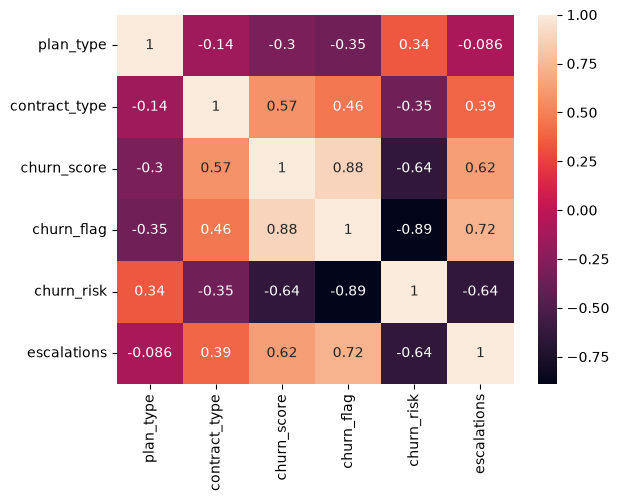

In [125]:
sns.heatmap(df_encoded.corr(), annot=True)

In [126]:
# above is incorrect method of encoding - as numbers are not assigned based on priority

In [130]:
# correct method of encoding - based on priority

df_encoded = df_visual[['plan_type', 'contract_type','churn_score','churn_flag','churn_risk', 'escalations']]

order_mappings = {'plan_type' : ['Basic','Standard','Premium'],
                  'contract_type' : ['Monthly','Annual'],
                  'churn_risk' : ['Low','Medium','High']
                 }

for col,order  in order_mappings.items():
    df_encoded[col] = pd.Categorical(df_encoded[col].astype('category'), categories = order, ordered = True).codes

In [131]:
df_encoded.head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,1,1,12,0,0,0
1,2,1,91,1,2,0
2,2,1,91,1,2,1
3,0,0,34,0,0,0
4,2,1,8,0,0,0


<Axes: >

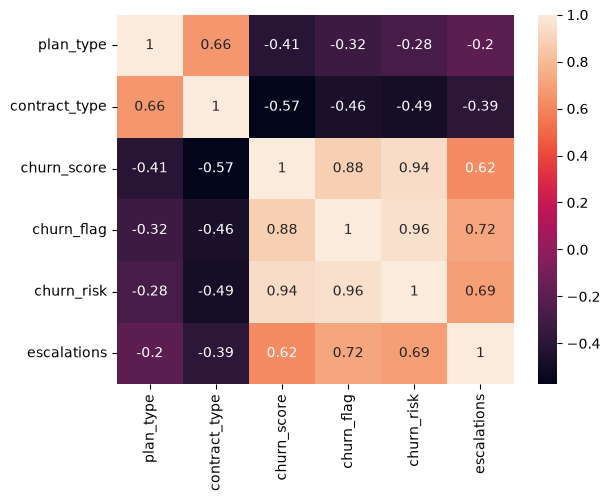

In [132]:
sns.heatmap(df_encoded.corr(), annot=True)

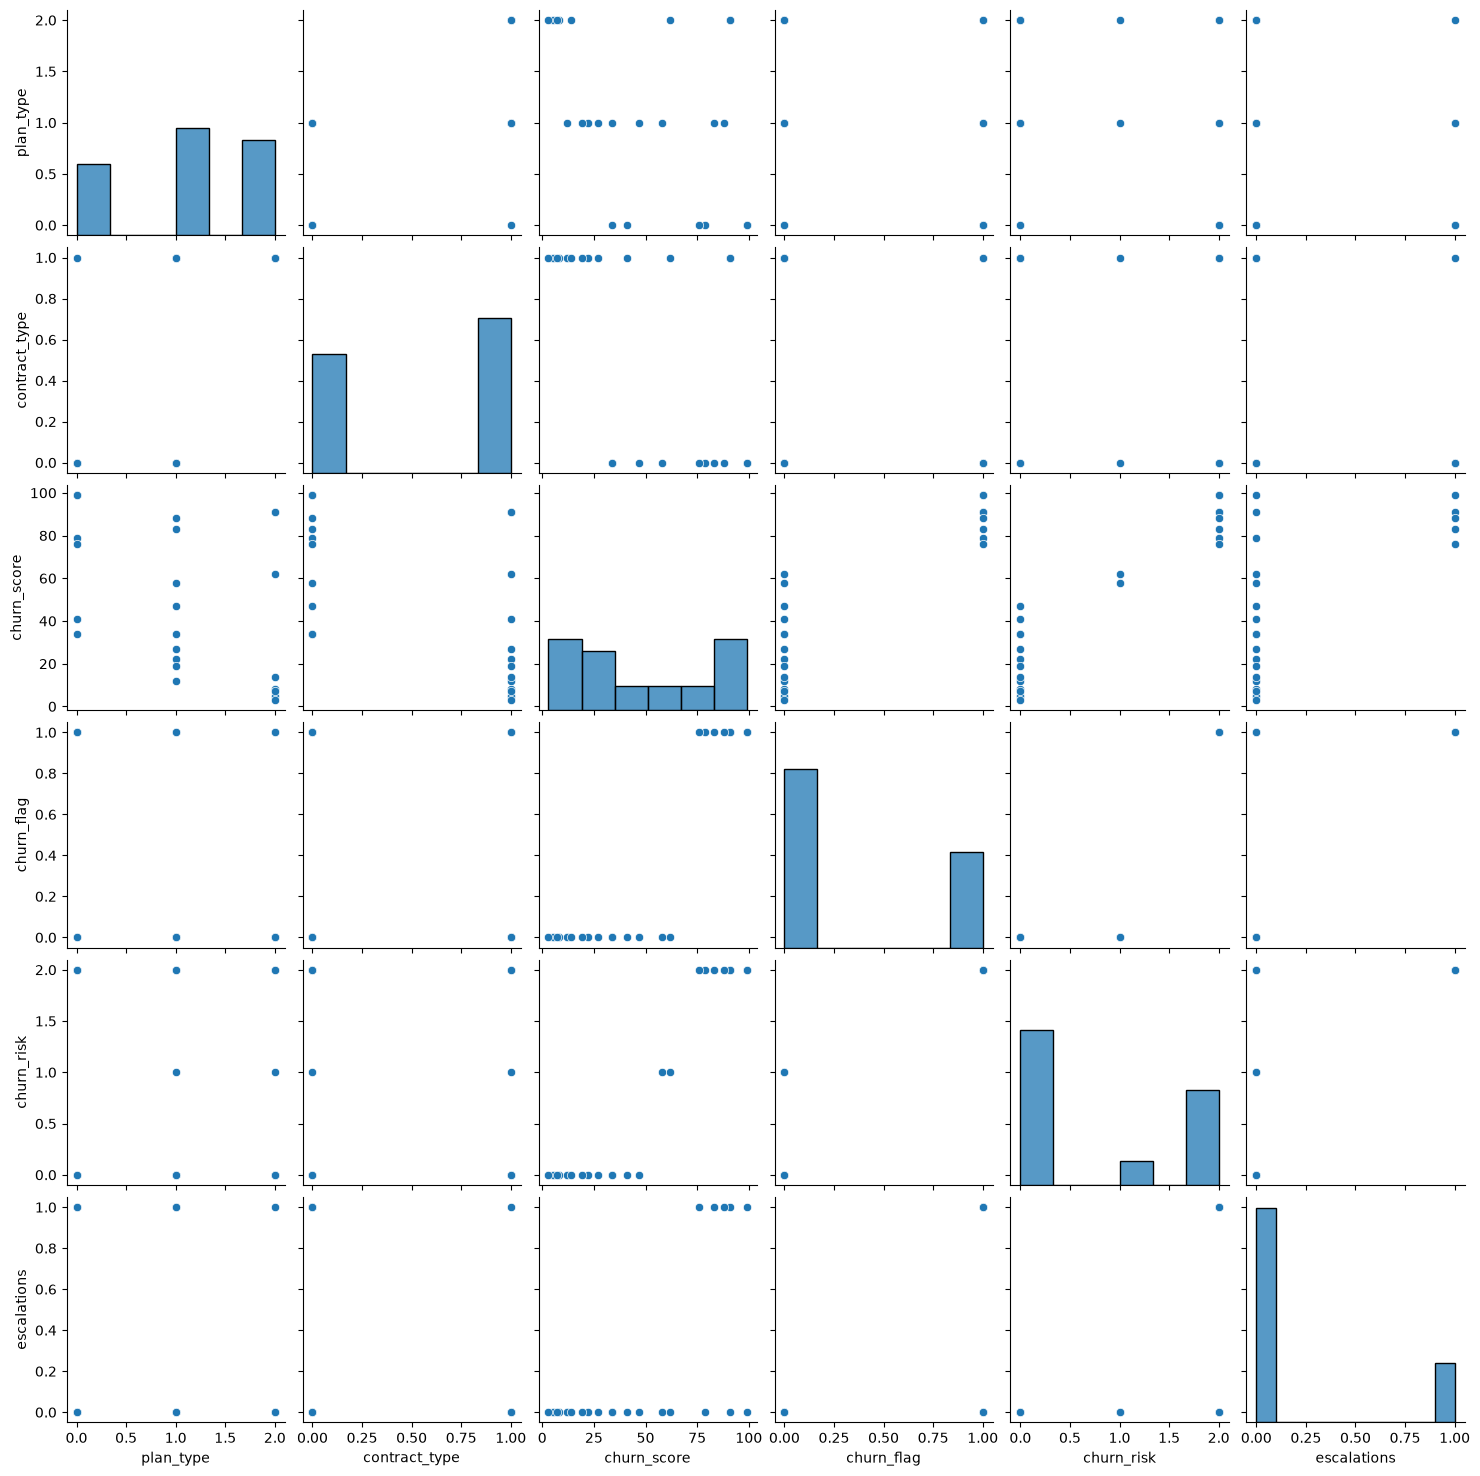

In [133]:
#pairplot
sns.pairplot(df_encoded)

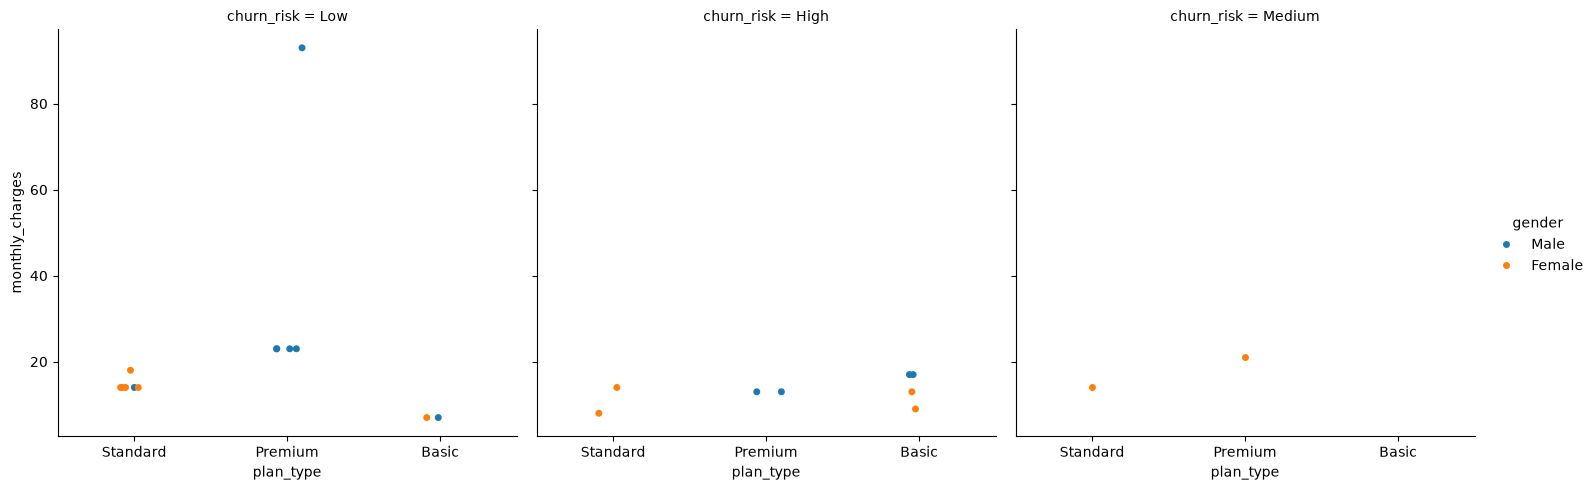

In [135]:
# catplot/facegrid plot
sns.catplot(data = df_visual,
    x='plan_type',
    y='monthly_charges',
    hue='gender',
    col='churn_risk',
)

In [137]:
# Pivot Table

pd.pivot_table(
    data = df_visual,
     values='churn_flag',
    index='plan_type',
    aggfunc= 'mean' 
).reset_index()

,plan_type,churn_flag
0,Basic,0.666667
1,Premium,0.250000
2,Standard,0.222222


In [139]:
pd.pivot_table(
    data = df_visual,
    index='plan_type',
     values=['churn_flag','monthly_charges','customerid'],
    aggfunc= {
        'monthly_charges' : 'sum',
        'customerid' : 'nunique',
        'churn_flag' : 'mean'
    }
).reset_index()

,plan_type,churn_flag,customerid,monthly_charges
0,Basic,0.666667,5,69.94
1,Premium,0.250000,7,231.92
2,Standard,0.222222,9,123.91


In [ ]:
# working with SQL in python (pandas)

In [141]:
#create db in SQL
conn = sqlite3.connect('test_database.sqlite')

#table details
conn.execute("CREATE TABLE users (first_name TEXT, country TEXT, budget INTEGER)")

#commit and save
conn.commit()

In [142]:
#insert data
cursor = conn.cursor()

#write sql query to insert records in sql table
cursor.execute(
    """
       INSERT INTO users VALUES 
       ('Madhav','India',25000),
       ('Rita','US',50000),
       ('Sam','AUS',30000)
    """
)

conn.commit()

In [144]:
#check inserted data in table 
conn = sqlite3.connect('test_database.sqlite')
query = """SELECT * FROM users"""

db_result = pd.read_sql(query, conn)
db_result.head()

,first_name,country,budget
0,Madhav,India,25000
1,Rita,US,50000
2,Sam,AUS,30000


In [146]:
#aggregation 
query = """SELECT country,sum(budget) as total_budget
        FROM users
        GROUP BY country
        """
db_agg = pd.read_sql(query, conn)
db_agg.head()

,country,total_budget
0,AUS,30000
1,India,25000
2,US,50000


In [148]:
conn.close()